
# SWYNEX Final Data Analytics Project

## End-to-End Online Retail Business Analysis

**Internship:** SWYNEX Data Analytics Internship

### Business Problem

Analyze historical online retail transactions to understand revenue,
product performance, customer purchasing behaviour, geographic
performance and transaction quality.

### Project Objectives

- Prepare and validate transaction data.
- Analyze sales and monthly revenue trends.
- Identify top products and countries.
- Understand customer purchase frequency.
- Review cancellations, returns and data quality.
- Develop business recommendations.

### Tools

Python, Pandas, NumPy, Matplotlib, Plotly and Streamlit.


In [1]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

candidates = [
    Path("/content/drive/MyDrive/SWYNEX-Final-Data-Analytics-Project"),
    Path.cwd(),
    *Path.cwd().parents
]

project = next(
    (
        p for p in candidates
        if (p / "data/cleaned_online_retail.csv.gz").exists()
    ),
    None
)

if project is None:
    raise FileNotFoundError(
        "Project data not found. Open this notebook from the project folder."
    )

data_path = project / "data/cleaned_online_retail.csv.gz"
charts_path = project / "visuals/charts"
charts_path.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(data_path, compression="gzip")
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

print("Dataset dimensions:", df.shape)
display(df.head())


Dataset dimensions: (536641, 11)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TransactionType,TotalAmount,DataQualityFlag
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,Sale,15.30,Normal
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,Sale,20.34,Normal
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,Sale,22.00,Normal
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,Sale,20.34,Normal
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,Sale,20.34,Normal



## 1. Data Quality Review


In [2]:

print("Missing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("Duplicate records:", df.duplicated().sum())

print("Transaction types:")
display(df["TransactionType"].value_counts().to_frame("Records"))

print("Data quality flags:")
display(df["DataQualityFlag"].value_counts().to_frame("Records"))


Missing values:


,Missing Values
InvoiceNo,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135037
Country,0
TransactionType,0
TotalAmount,0


Duplicate records: 0
Transaction types:


,Records
TransactionType,
Sale,524877
Cancellation,9251
Return,1336
Zero Price,1174
Bad Debt Adjustment,3


Data quality flags:


,Records
DataQualityFlag,
Normal,535367
Zero Price - Review,1174
Unknown Description,97
Accounting Adjustment,3



## 2. Sales Performance

Sales analysis includes Sale transactions with positive quantities and prices.


In [3]:

sales = df[
    (df["TransactionType"] == "Sale") &
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

sales["Month"] = sales["InvoiceDate"].dt.to_period("M").astype(str)
sales["Weekday"] = sales["InvoiceDate"].dt.day_name()
sales["Hour"] = sales["InvoiceDate"].dt.hour

revenue = sales["TotalAmount"].sum()
orders = sales["InvoiceNo"].nunique()
customers = sales["CustomerID"].nunique()

kpis = pd.DataFrame({
    "Metric": [
        "Valid sales records", "Revenue (£)", "Orders",
        "Customers", "Products", "Quantity sold", "Average order value (£)"
    ],
    "Value": [
        len(sales), round(revenue, 2), orders, customers,
        sales["StockCode"].nunique(), sales["Quantity"].sum(),
        round(revenue / orders, 2)
    ]
})

display(kpis)


,Metric,Value
0,Valid sales records,524877.00
1,Revenue (£),10631048.74
2,Orders,19959.00
3,Customers,4338.00
4,Products,3921.00
5,Quantity sold,5572419.00
6,Average order value (£),532.64



## 3. Monthly Revenue


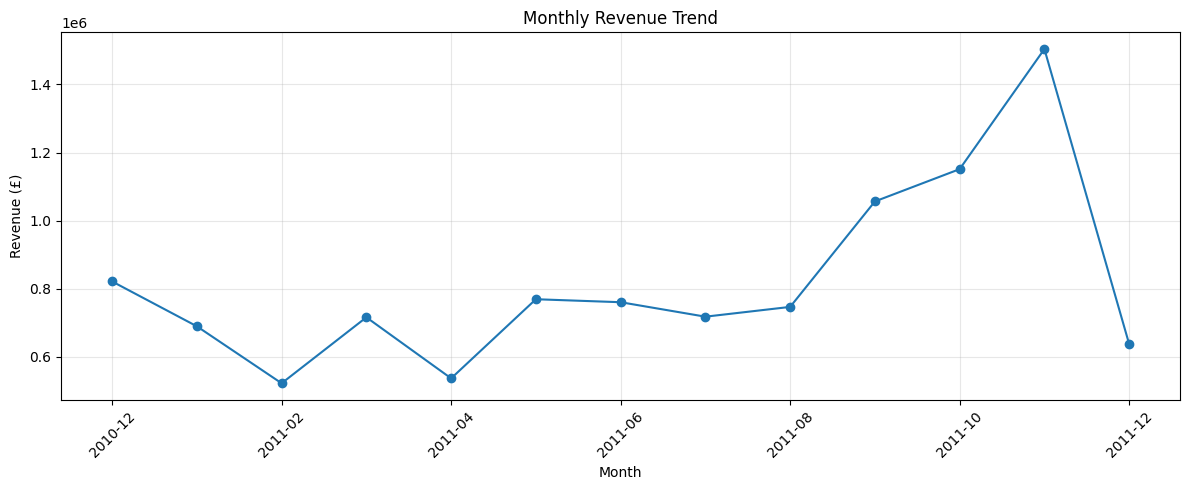

,Revenue
Month,
2010-12,821452.73
2011-01,689811.61
2011-02,522545.56
2011-03,716215.26
2011-04,536968.49
2011-05,769296.61
2011-06,760547.01
2011-07,718076.12
2011-08,746779.32


In [4]:

monthly = sales.groupby("Month")["TotalAmount"].sum()

monthly.plot(figsize=(12, 5), marker="o")
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(charts_path / "monthly_revenue.png", dpi=150)
plt.show()

display(monthly.to_frame("Revenue").round(2))



## 4. Country Performance


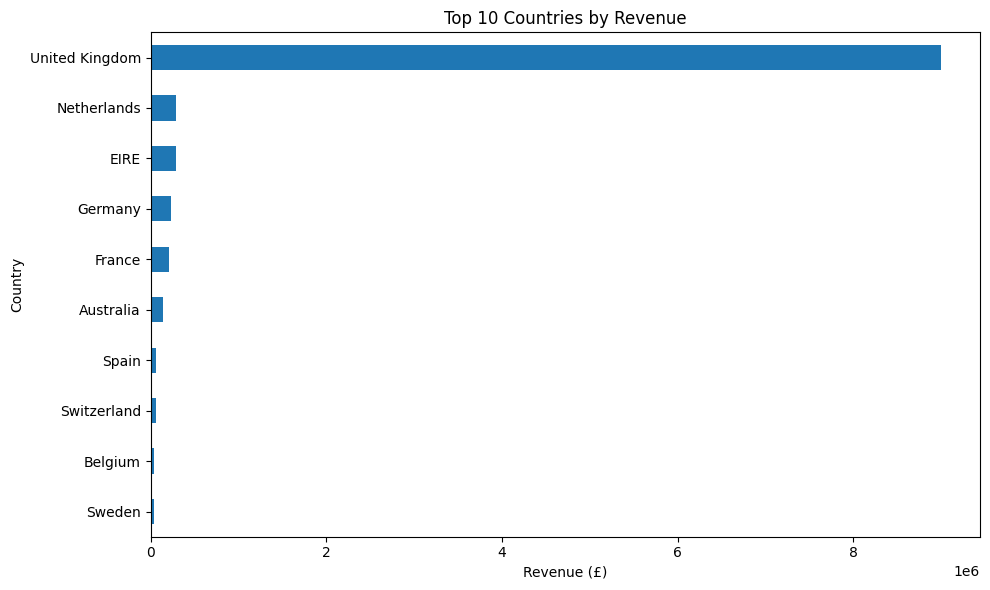

,Revenue
Country,
United Kingdom,8990682.03
Netherlands,285446.34
EIRE,283140.52
Germany,228678.40
France,209625.37
Australia,138453.81
Spain,61558.56
Switzerland,57067.60
Belgium,41196.34


United Kingdom revenue share: 84.57 %


In [5]:

country = sales.groupby("Country")["TotalAmount"].sum()
top_country = country.nlargest(10).sort_values()

top_country.plot(kind="barh", figsize=(10, 6))
plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.tight_layout()
plt.savefig(charts_path / "top_countries_revenue.png", dpi=150)
plt.show()

display(country.sort_values(ascending=False).head(10).to_frame("Revenue"))
print(
    "United Kingdom revenue share:",
    round(country.get("United Kingdom", 0) / revenue * 100, 2),
    "%"
)



## 5. Product Performance


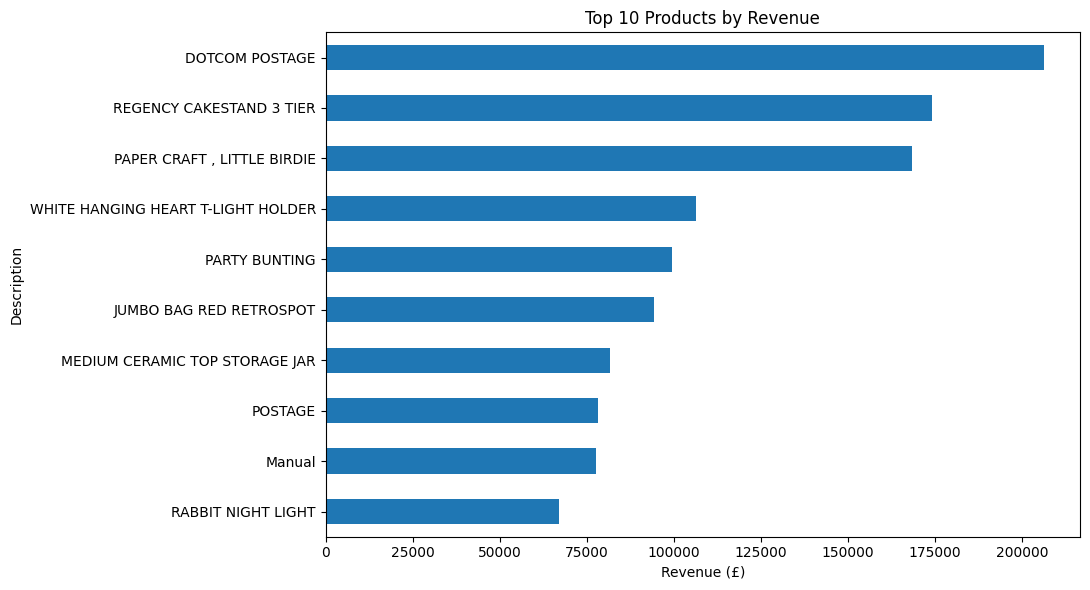

,Quantity_Sold,Revenue,Orders
Description,,,
DOTCOM POSTAGE,706,206248.77,706
REGENCY CAKESTAND 3 TIER,13851,174156.54,1988
"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1
WHITE HANGING HEART T-LIGHT HOLDER,37872,106236.72,2256
PARTY BUNTING,18283,99445.23,1685
JUMBO BAG RED RETROSPOT,48371,94159.81,2089
MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92,247
POSTAGE,3150,78101.88,1126
Manual,6985,77752.82,290


In [6]:

product_summary = sales.groupby("Description").agg(
    Quantity_Sold=("Quantity", "sum"),
    Revenue=("TotalAmount", "sum"),
    Orders=("InvoiceNo", "nunique")
)

top_products = product_summary.nlargest(10, "Revenue")

top_products["Revenue"].sort_values().plot(
    kind="barh", figsize=(11, 6)
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.tight_layout()
plt.savefig(charts_path / "top_products_revenue.png", dpi=150)
plt.show()

display(top_products.round(2))



## 6. Customer Purchasing Behaviour


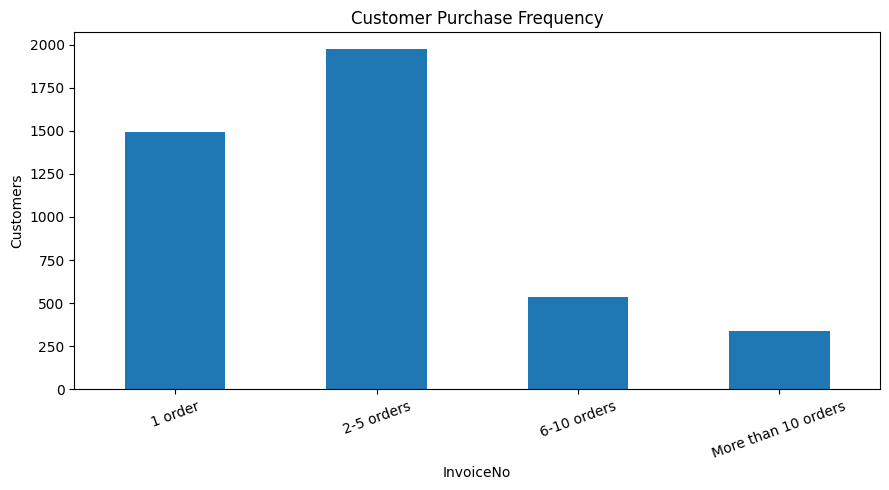

,Customers
InvoiceNo,
1 order,1493
2-5 orders,1973
6-10 orders,535
More than 10 orders,337


Repeat customer share: 65.58 %


In [7]:

customer_orders = (
    sales.dropna(subset=["CustomerID"])
    .groupby("CustomerID")["InvoiceNo"]
    .nunique()
)

segments = pd.cut(
    customer_orders,
    bins=[0, 1, 5, 10, np.inf],
    labels=["1 order", "2-5 orders", "6-10 orders", "More than 10 orders"]
)

segment_counts = segments.value_counts().reindex(
    ["1 order", "2-5 orders", "6-10 orders", "More than 10 orders"],
    fill_value=0
)

segment_counts.plot(kind="bar", figsize=(9, 5))
plt.title("Customer Purchase Frequency")
plt.ylabel("Customers")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(charts_path / "customer_purchase_frequency.png", dpi=150)
plt.show()

display(segment_counts.to_frame("Customers"))

repeat_share = (customer_orders > 1).mean() * 100
print("Repeat customer share:", round(repeat_share, 2), "%")



## 7. Transaction Quality


In [8]:

display(
    df.groupby("TransactionType")["TotalAmount"]
    .agg(["count", "sum"])
    .round(2)
)

returns = df[df["TransactionType"] == "Return"]
cancellations = df[df["TransactionType"] == "Cancellation"]

print("Return records:", len(returns))
print("Cancellation records:", len(cancellations))
print("Cancellation invoices:", cancellations["InvoiceNo"].nunique())
print("Return amount recorded:", returns["TotalAmount"].sum())

print(
    "Note: Return transactions have negative quantities but zero TotalAmount. "
    "Their monetary return value cannot be inferred from this field."
)


,count,sum
TransactionType,,
Bad Debt Adjustment,3,-11062.06
Cancellation,9251,-893979.73
Return,1336,0.00
Sale,524877,10631048.74
Zero Price,1174,0.00


Return records: 1336
Cancellation records: 9251
Cancellation invoices: 3836
Return amount recorded: 0.0
Note: Return transactions have negative quantities but zero TotalAmount. Their monetary return value cannot be inferred from this field.



## 8. Time-Based Sales Analysis


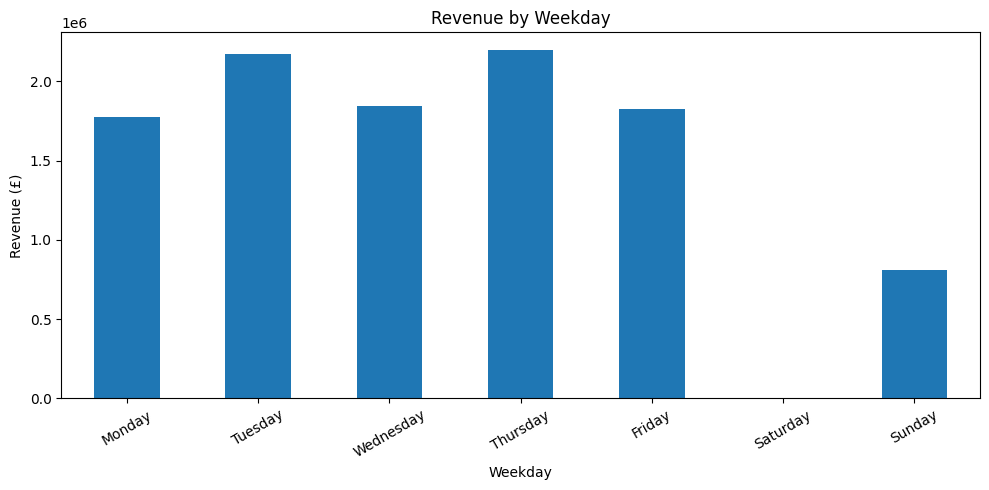

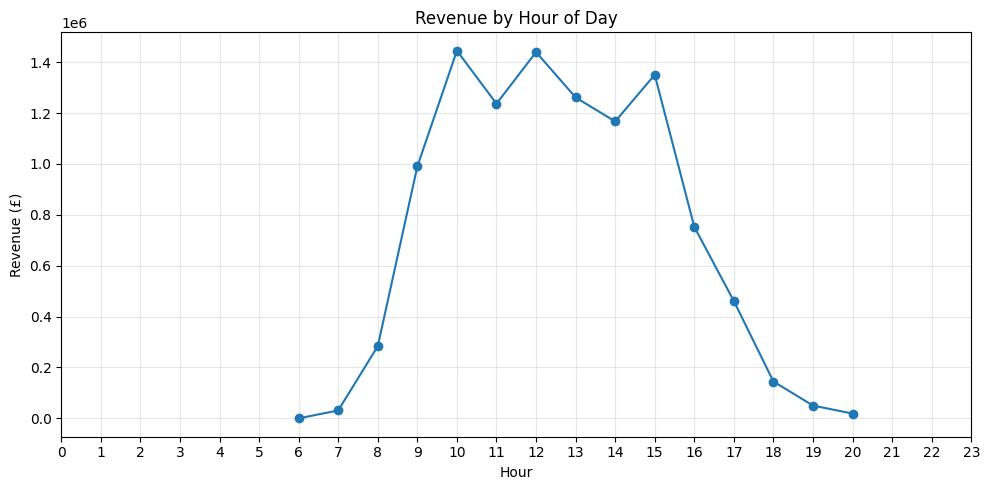

In [9]:

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday = sales.groupby("Weekday")["TotalAmount"].sum()
weekday = weekday.reindex(weekday_order)

weekday.plot(kind="bar", figsize=(10, 5))
plt.title("Revenue by Weekday")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(charts_path / "weekday_revenue.png", dpi=150)
plt.show()

hourly = sales.groupby("Hour")["TotalAmount"].sum()

hourly.plot(figsize=(10, 5), marker="o")
plt.title("Revenue by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("Revenue (£)")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(charts_path / "hourly_revenue.png", dpi=150)
plt.show()



## 9. Key Findings

- Valid sales generated approximately £10.63 million in revenue.
- November 2011 recorded the highest monthly revenue.
- The United Kingdom contributed approximately 84.57% of revenue.
- Approximately 65.58% of identified customers placed repeat orders.
- High product quantities can be influenced by individual bulk orders.
- Cancellations and returns should be monitored separately from sales.

## 10. Business Recommendations

1. Introduce customer loyalty campaigns to encourage repeat purchases.
2. Explore markets beyond the United Kingdom.
3. Use product demand trends to improve inventory planning.
4. Prepare promotions ahead of strong seasonal sales periods.
5. Monitor cancellation patterns and unusual transaction quantities.
6. Improve completeness of customer information.

## 11. Limitations

- The data covers December 2010 to December 2011.
- December 2011 is a partial month, ending December 9.
- Customer-level analysis excludes missing CustomerID records.
- Return records have zero TotalAmount, so return monetary value is unavailable.
- Large individual orders can affect quantity-based product rankings.

## 12. Conclusion

This project demonstrates an end-to-end data analytics workflow,
from data preparation and exploratory analysis to interactive
dashboard development. The results provide insights that can
support data-driven retail business decisions.
